# Global Technology Market Intelligence: Sizing & Competitive Benchmarking

## 1. Data Collection & Preparation

In [1]:
# Import the pandas library for data manipulation
import pandas as pd

# Define the path to the Excel file
file_path = "../sources/source_register.xlsx"

# Load the two sheets into separate dataframes
df_smartphone = pd.read_excel(file_path, sheet_name="Raw_Smartphone")
df_cloud = pd.read_excel(file_path, sheet_name="Raw_Cloud")

# Display the first few rows of the smartphone dataframe to check it loaded correctly
df_smartphone.head()

,Year,Vendor,Metric,Value,Unit,Source ID
0,2024,Apple,Shipments,232.4,Millions of Units,SRC-SP-01
1,2024,Samsung,Shipments,223.4,Millions of Units,SRC-SP-01
2,2024,Xiaomi,Shipments,168.5,Millions of Units,SRC-SP-01
3,2024,Transsion,Shipments,106.4,Millions of Units,SRC-SP-01
4,2024,OPPO,Shipments,104.0,Millions of Units,SRC-SP-01


In [2]:
# 1. Separate the Total Market data from the individual vendors
df_sp_total = df_smartphone[df_smartphone['Vendor'] == 'Total Market'].copy()
df_sp_vendors = df_smartphone[df_smartphone['Vendor'] != 'Total Market'].copy()

df_cl_total = df_cloud[df_cloud['Vendor'] == 'Total Market'].copy()
df_cl_vendors = df_cloud[df_cloud['Vendor'] != 'Total Market'].copy()

# 2. Merge the Total Market data back into the vendor data so we can do math
df_sp_clean = df_sp_vendors.merge(df_sp_total[['Year', 'Value']], on='Year', suffixes=('', '_Total'))
df_cl_clean = df_cl_vendors.merge(df_cl_total[['Year', 'Value']], on='Year', suffixes=('', '_Total'))

# 3. Calculate Market Share (%)
df_sp_clean['Market_Share_%'] = (df_sp_clean['Value'] / df_sp_clean['Value_Total']) * 100
df_cl_clean['Market_Share_%'] = (df_cl_clean['Value'] / df_cl_clean['Value_Total']) * 100

# 4. Sort the data so it looks professional (by Year, then by highest Market Share)
df_sp_clean = df_sp_clean.sort_values(by=['Year', 'Market_Share_%'], ascending=[True, False])
df_cl_clean = df_cl_clean.sort_values(by=['Year', 'Market_Share_%'], ascending=[True, False])

# 5. Show the newly cleaned Smartphone data
df_sp_clean.head(10)

,Year,Vendor,Metric,Value,Unit,Source ID,Value_Total,Market_Share_%
28,2020,Samsung,Shipments,266.7,Millions of Units,SRC-SP-05,1292.0,20.642415
29,2020,Apple,Shipments,206.1,Millions of Units,SRC-SP-05,1292.0,15.952012
30,2020,Xiaomi,Shipments,147.8,Millions of Units,SRC-SP-05,1292.0,11.439628
31,2020,OPPO,Shipments,111.8,Millions of Units,SRC-SP-05,1292.0,8.653251
32,2020,Vivo,Shipments,111.6,Millions of Units,SRC-SP-05,1292.0,8.637771
33,2020,Transsion,Shipments,51.0,Millions of Units,SRC-SP-05,1292.0,3.947368
34,2020,Lenovo,Shipments,42.0,Millions of Units,SRC-SP-05,1292.0,3.250774
21,2021,Samsung,Shipments,272.0,Millions of Units,SRC-SP-04,1355.0,20.073801
22,2021,Apple,Shipments,235.7,Millions of Units,SRC-SP-04,1355.0,17.394834
23,2021,Xiaomi,Shipments,191.0,Millions of Units,SRC-SP-04,1355.0,14.095941


In [3]:
# 1. Calculate Year-over-Year (YoY) Growth % for Smartphones
# We group by Vendor, and use pct_change() to compare to the previous year
df_sp_clean['YoY_Growth_%'] = df_sp_clean.groupby('Vendor')['Value'].pct_change() * 100

# 2. Calculate Year-over-Year (YoY) Growth % for Cloud
df_cl_clean['YoY_Growth_%'] = df_cl_clean.groupby('Vendor')['Value'].pct_change() * 100

# 3. Let's look specifically at the smartphone data for 2023 and 2024
# We round the numbers to 2 decimal places so it looks clean
df_sp_clean[['Year', 'Vendor', 'Value', 'YoY_Growth_%', 'Market_Share_%']].tail(15).round(2)

,Year,Vendor,Value,YoY_Growth_%,Market_Share_%
20,2022,Lenovo,43.7,-19.07,3.63
7,2023,Apple,234.6,3.62,20.22
8,2023,Samsung,226.6,-13.15,19.53
9,2023,Xiaomi,145.9,-4.70,12.58
10,2023,OPPO,99.4,-3.87,8.57
12,2023,Transsion,94.9,26.53,8.18
11,2023,Vivo,93.5,-5.56,8.06
13,2023,Lenovo,58.4,33.64,5.03
0,2024,Apple,232.4,-0.94,18.68
1,2024,Samsung,223.4,-1.41,17.96


In [4]:
# 1. Define the path to save the processed files
# (We go up one level to 'Tech-Market-Intelligence-Platform', then into 'data/processed')
save_path = "../data/processed/"

# 2. Save the cleaned Smartphone data
df_sp_clean.to_csv(save_path + "clean_smartphone.csv", index=False)

# 3. Save the cleaned Cloud data
df_cl_clean.to_csv(save_path + "clean_cloud.csv", index=False)

print("Success! Data saved to the processed folder.")

Success! Data saved to the processed folder.


## 2. Market Analysis & Visualization

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visual style for the charts
sns.set_theme(style="whitegrid")

C:\Users\dell\AppData\Local\Temp\ipykernel_13368\1731100786.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Market_Share_%', y='Vendor', data=df_2024, palette='Blues_r')


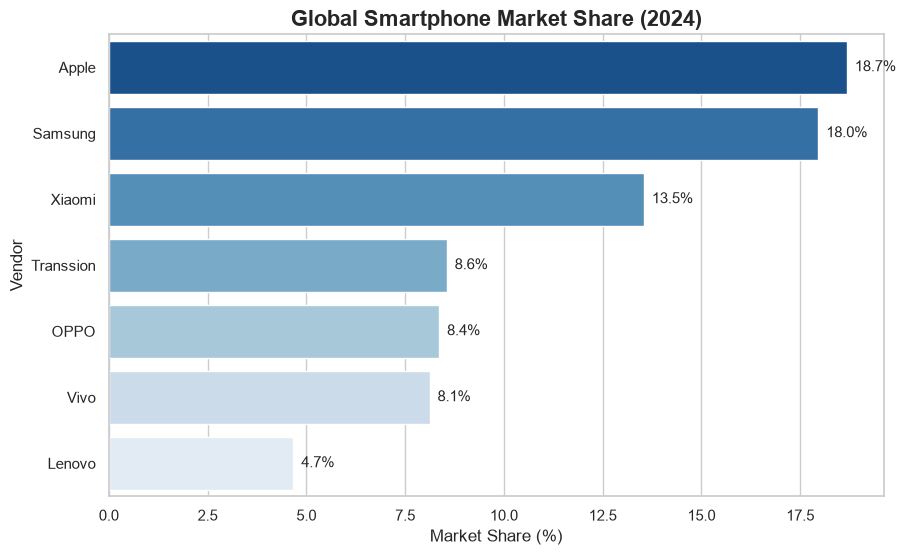

In [6]:
# Filter data for the year 2024 and sort it so the largest is at the top
df_2024 = df_sp_clean[df_sp_clean['Year'] == 2024].sort_values(by='Market_Share_%', ascending=False)

# Create the figure
plt.figure(figsize=(10, 6))

# Draw the bar chart
sns.barplot(x='Market_Share_%', y='Vendor', data=df_2024, palette='Blues_r')

# Add titles and labels
plt.title('Global Smartphone Market Share (2024)', fontsize=16, fontweight='bold')
plt.xlabel('Market Share (%)', fontsize=12)
plt.ylabel('Vendor', fontsize=12)

# Add the percentage numbers to the end of each bar
for index, value in enumerate(df_2024['Market_Share_%']):
    plt.text(value + 0.2, index, f'{value:.1f}%', va='center', fontsize=11)

# Display the chart
plt.show()

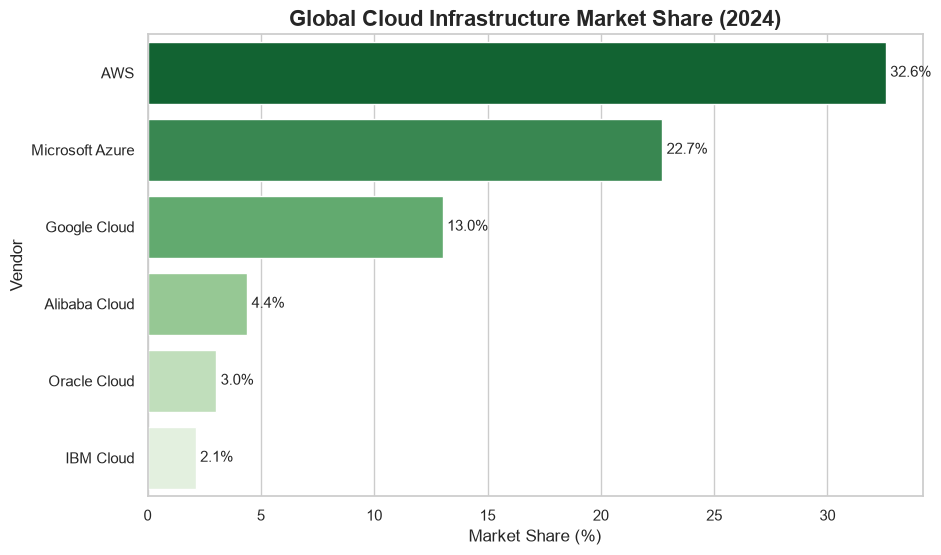

In [7]:
# Filter cloud data for 2024 and sort it
df_cloud_2024 = df_cl_clean[df_cl_clean['Year'] == 2024].sort_values(by='Market_Share_%', ascending=False)

# Create the figure
plt.figure(figsize=(10, 6))

# Draw the bar chart (using a green color scheme for Cloud)
sns.barplot(x='Market_Share_%', y='Vendor', data=df_cloud_2024, hue='Vendor', palette='Greens_r', legend=False)

# Add titles and labels
plt.title('Global Cloud Infrastructure Market Share (2024)', fontsize=16, fontweight='bold')
plt.xlabel('Market Share (%)', fontsize=12)
plt.ylabel('Vendor', fontsize=12)

# Add the percentage numbers to the end of each bar
for index, value in enumerate(df_cloud_2024['Market_Share_%']):
    plt.text(value + 0.2, index, f'{value:.1f}%', va='center', fontsize=11)

# Display the chart
plt.show()

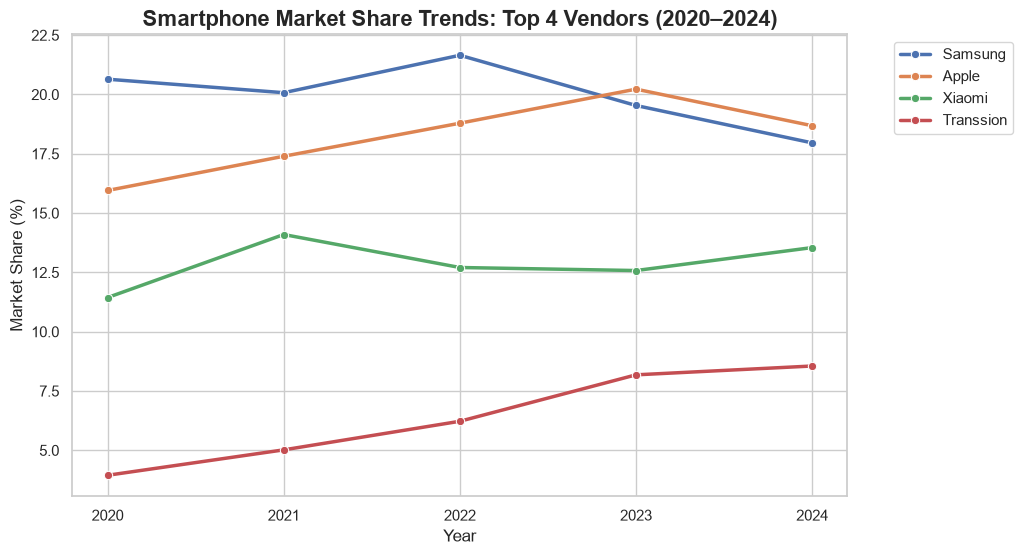

In [8]:
# Create a figure
plt.figure(figsize=(10, 6))

# Filter only for the Top 4 vendors to keep the chart clean
top_4 = ['Apple', 'Samsung', 'Xiaomi', 'Transsion']
df_top4 = df_sp_clean[df_sp_clean['Vendor'].isin(top_4)]

# Draw the line chart
sns.lineplot(data=df_top4, x='Year', y='Market_Share_%', hue='Vendor', marker='o', linewidth=2.5)

# Add titles and labels
plt.title('Smartphone Market Share Trends: Top 4 Vendors (2020–2024)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Market Share (%)', fontsize=12)

# Move the legend outside the chart so it doesn't block the lines
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Ensure the x-axis only shows whole years
plt.xticks([2020, 2021, 2022, 2023, 2024])

# Display the chart
plt.show()

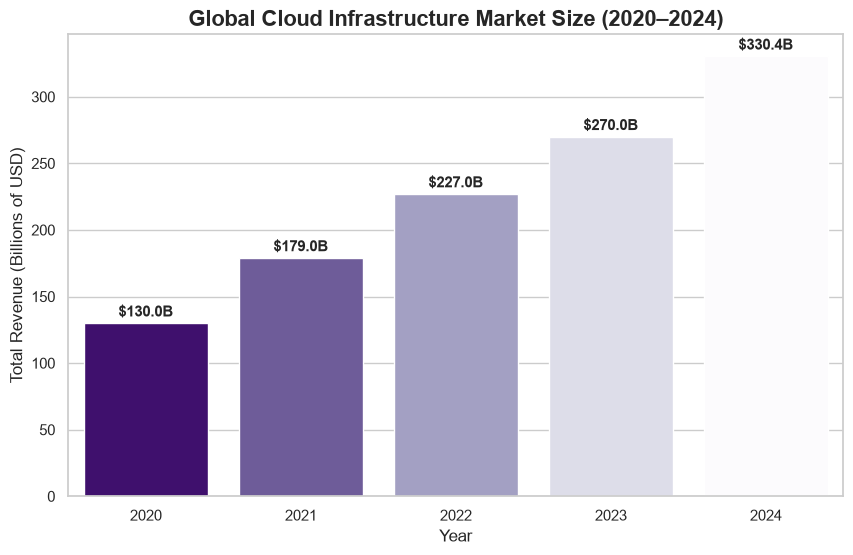

In [9]:
# Filter the data to get only the Total Market for each year
df_cloud_total = df_cl_total.sort_values(by='Year')

# Create the figure
plt.figure(figsize=(10, 6))

# Draw a bar chart showing total revenue
sns.barplot(data=df_cloud_total, x='Year', y='Value', hue='Year', palette='Purples_r', legend=False)

# Add titles and labels
plt.title('Global Cloud Infrastructure Market Size (2020–2024)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Revenue (Billions of USD)', fontsize=12)

# Add the exact dollar amount on top of each bar
for index, row in df_cloud_total.reset_index().iterrows():
    plt.text(index, row['Value'] + 5, f"${row['Value']}B", ha='center', fontsize=11, fontweight='bold')

# Display the chart
plt.show()

## 3. SQL Database & Queries

In [10]:
import sqlite3
import pandas as pd

# This creates a connection to a new SQLite database file
# The file will be saved in your project folder
conn = sqlite3.connect('../sql/market_intelligence.db')

print("Database connection created successfully!")

Database connection created successfully!


In [12]:
# 1. Drop the old broken tables
cursor.execute("DROP TABLE IF EXISTS smartphone_data")
cursor.execute("DROP TABLE IF EXISTS cloud_data")

# 2. Re-create the tables with the exact names Python is using
cursor.execute('''
    CREATE TABLE smartphone_data (
        Year INTEGER,
        Vendor TEXT,
        Value REAL,
        Market_Share_Pct REAL,
        YoY_Growth_Pct REAL
    )
''')

cursor.execute('''
    CREATE TABLE cloud_data (
        Year INTEGER,
        Vendor TEXT,
        Value REAL,
        Market_Share_Pct REAL,
        YoY_Growth_Pct REAL
    )
''')

# 3. Rename the python columns to match our SQL column names
# This ensures Python and SQL are speaking the exact same language
df_sp_final = df_sp_clean[['Year', 'Vendor', 'Value', 'Market_Share_%', 'YoY_Growth_%']].rename(
    columns={'Market_Share_%': 'Market_Share_Pct', 'YoY_Growth_%': 'YoY_Growth_Pct'}
)

df_cl_final = df_cl_clean[['Year', 'Vendor', 'Value', 'Market_Share_%', 'YoY_Growth_%']].rename(
    columns={'Market_Share_%': 'Market_Share_Pct', 'YoY_Growth_%': 'YoY_Growth_Pct'}
)

# 4. Load the renamed data into the SQL tables
df_sp_final.to_sql('smartphone_data', conn, if_exists='append', index=False)
df_cl_final.to_sql('cloud_data', conn, if_exists='append', index=False)

conn.commit()

print("Success! Tables created and data loaded.")

Success! Tables created and data loaded.


In [13]:
query_1 = """
SELECT 
    Vendor, 
    Value AS Shipments_Millions, 
    Market_Share_Pct,
    RANK() OVER (ORDER BY Market_Share_Pct DESC) as Market_Rank
FROM smartphone_data
WHERE Year = 2024;
"""

df_query_1 = pd.read_sql_query(query_1, conn)
df_query_1

,Vendor,Shipments_Millions,Market_Share_Pct,Market_Rank
0,Apple,232.4,18.681672,1
1,Samsung,223.4,17.958199,2
2,Xiaomi,168.5,13.545016,3
3,Transsion,106.4,8.553055,4
4,OPPO,104.0,8.360129,5
5,Vivo,101.0,8.118971,6
6,Lenovo,58.1,4.670418,7


In [14]:
query_2 = """
SELECT 
    Vendor, 
    ROUND(AVG(YoY_Growth_Pct), 2) AS Avg_YoY_Growth_Pct
FROM cloud_data
GROUP BY Vendor
ORDER BY Avg_YoY_Growth_Pct DESC;
"""

df_query_2 = pd.read_sql_query(query_2, conn)
df_query_2

,Vendor,Avg_YoY_Growth_Pct
0,Oracle Cloud,35.42
1,Google Cloud,35.06
2,Microsoft Azure,26.15
3,AWS,24.41
4,IBM Cloud,23.75
5,Alibaba Cloud,20.09


In [15]:
query_3 = """
WITH Share_2022 AS (
    SELECT Vendor, Market_Share_Pct as Share_2022
    FROM smartphone_data
    WHERE Year = 2022
),
Share_2024 AS (
    SELECT Vendor, Market_Share_Pct as Share_2024
    FROM smartphone_data
    WHERE Year = 2024
)
SELECT 
    s22.Vendor,
    ROUND(s22.Share_2022, 2) AS Share_2022_Pct,
    ROUND(s24.Share_2024, 2) AS Share_2024_Pct,
    ROUND(s24.Share_2024 - s22.Share_2022, 2) AS Share_Change_Pct
FROM Share_2022 s22
JOIN Share_2024 s24 ON s22.Vendor = s24.Vendor
ORDER BY Share_Change_Pct DESC;
"""

df_query_3 = pd.read_sql_query(query_3, conn)
df_query_3

,Vendor,Share_2022_Pct,Share_2024_Pct,Share_Change_Pct
0,Transsion,6.22,8.55,2.33
1,Lenovo,3.63,4.67,1.04
2,Xiaomi,12.71,13.55,0.84
3,Vivo,8.22,8.12,-0.10
4,Apple,18.79,18.68,-0.11
5,OPPO,8.58,8.36,-0.22
6,Samsung,21.65,17.96,-3.69


## 4. Market Sizing (TAM, SAM, SOM)

In [16]:
# 1. Set the base TAM (Total Market in 2024)
total_market_2024 = 1244.0 # in millions

# 2. Assume the premium segment (SAM) is 25% of the market
premium_percentage = 0.25
sam_2024 = total_market_2024 * premium_percentage

# 3. Apple's actual shipments (SOM)
som_apple = 232.4

# 4. Calculate Apple's capture rate of the SAM
capture_rate = (som_apple / sam_2024) * 100

print(f"--- 2024 Market Sizing (Apple) ---")
print(f"TAM (Total Global Market): {total_market_2024} million units")
print(f"SAM (Premium Segment @ {premium_percentage*100}%): {sam_2024} million units")
print(f"SOM (Apple's Actual Shipments): {som_apple} million units")
print(f"Apple's capture rate of SAM: {capture_rate:.2f}%")

# 5. Sensitivity Analysis: What if the premium segment is different?
print("\n--- Sensitivity Analysis ---")
for pct in [0.20, 0.25, 0.30]:
    simulated_sam = total_market_2024 * pct
    simulated_capture = (som_apple / simulated_sam) * 100
    print(f"If premium segment is {pct*100}%: SAM is {simulated_sam:.1f} million units, Apple captures {simulated_capture:.2f}%")

--- 2024 Market Sizing (Apple) ---
TAM (Total Global Market): 1244.0 million units
SAM (Premium Segment @ 25.0%): 311.0 million units
SOM (Apple's Actual Shipments): 232.4 million units
Apple's capture rate of SAM: 74.73%

--- Sensitivity Analysis ---
If premium segment is 20.0%: SAM is 248.8 million units, Apple captures 93.41%
If premium segment is 25.0%: SAM is 311.0 million units, Apple captures 74.73%
If premium segment is 30.0%: SAM is 373.2 million units, Apple captures 62.27%


## 5. Competitive Benchmarking & Market Concentration

In [17]:
# 1. Function to calculate CR4 and HHI
def calculate_concentration(df, year):
    # Filter for the specific year
    df_year = df[df['Year'] == year].copy()
    
    # Sort by market share descending
    df_year = df_year.sort_values(by='Market_Share_%', ascending=False)
    
    # Calculate CR4 (Top 4 vendors combined share)
    cr4 = df_year['Market_Share_%'].head(4).sum()
    
    # Calculate HHI (Sum of squares of all market shares)
    # We multiply by 100 to make it a whole number (standard practice)
    hhi = (df_year['Market_Share_%'] ** 2).sum()
    
    return cr4, hhi

# 2. Calculate for Smartphones 2024
sp_cr4, sp_hhi = calculate_concentration(df_sp_clean, 2024)

# 3. Calculate for Cloud 2024
cloud_cr4, cloud_hhi = calculate_concentration(df_cl_clean, 2024)

# 4. Print the results
print("--- 2024 Market Concentration ---")
print(f"Smartphone CR4 (Top 4 share): {sp_cr4:.2f}%")
print(f"Smartphone HHI: {sp_hhi:.2f}")
print(f"Cloud CR4 (Top 4 share): {cloud_cr4:.2f}%")
print(f"Cloud HHI: {cloud_hhi:.2f}")

print("\n--- Interpretation ---")
print("HHI < 1500 = Competitive Market")
print("HHI 1500 to 2500 = Moderately Concentrated")
print("HHI > 2500 = Highly Concentrated (Oligopoly)")

--- 2024 Market Concentration ---
Smartphone CR4 (Top 4 share): 58.74%
Smartphone HHI: 1085.75
Cloud CR4 (Top 4 share): 72.67%
Cloud HHI: 1778.15

--- Interpretation ---
HHI < 1500 = Competitive Market
HHI 1500 to 2500 = Moderately Concentrated
HHI > 2500 = Highly Concentrated (Oligopoly)


## 6. Forecasting & Scenario Analysis (2025–2027)

In [18]:
# 1. Calculate the historical CAGR for the Cloud Market (2020 to 2024)
start_val = 130.0 # 2020 Total Market
end_val = 330.4   # 2024 Total Market
years = 4

cagr = (end_val / start_val) ** (1 / years) - 1
print(f"Historical Cloud Market CAGR (2020-2024): {cagr * 100:.2f}%\n")

# 2. Set up the scenarios
# Base Case: Grow at the historical average
base_growth = cagr 
# Bull Case: AI adoption accelerates growth by 5% above average
bull_growth = cagr + 0.05 
# Bear Case: Economic slowdown drops growth 5% below average
bear_growth = cagr - 0.05 

# 3. Create the forecast lists starting with the 2024 actual
forecast_years = [2024, 2025, 2026, 2027]
base_forecast = [end_val]
bull_forecast = [end_val]
bear_forecast = [end_val]

# 4. Calculate the compounding growth for 2025, 2026, and 2027
for i in range(3):
    base_forecast.append(base_forecast[-1] * (1 + base_growth))
    bull_forecast.append(bull_forecast[-1] * (1 + bull_growth))
    bear_forecast.append(bear_forecast[-1] * (1 + bear_growth))

# 5. Put it into a DataFrame for easy viewing
df_forecast = pd.DataFrame({
    'Year': forecast_years,
    'Base_Case_USD_Billions': [round(x, 1) for x in base_forecast],
    'Bull_Case_USD_Billions': [round(x, 1) for x in bull_forecast],
    'Bear_Case_USD_Billions': [round(x, 1) for x in bear_forecast]
})

df_forecast

Historical Cloud Market CAGR (2020-2024): 26.26%



,Year,Base_Case_USD_Billions,Bull_Case_USD_Billions,Bear_Case_USD_Billions
0,2024,330.4,330.4,330.4
1,2025,417.2,433.7,400.7
2,2026,526.7,569.3,485.8
3,2027,665.1,747.2,589.1


## 7. Exporting Data for Excel Dashboards

In [19]:
# Export the tables we just calculated to CSV files in the Excel folder
df_forecast.to_csv('../excel/forecast_data.csv', index=False)
df_sp_clean.to_csv('../excel/smartphone_dashboard_data.csv', index=False)
df_cl_clean.to_csv('../excel/cloud_dashboard_data.csv', index=False)

print("Data exported to the Excel folder successfully!")

Data exported to the Excel folder successfully!
